# Демо 1. Класичне донавчання: зміна голови в моделі BERT

У цьому ноутбуці донавчаємо модель **BERT** для задачі **визначення парафраз**: модель отримує два речення й визначає, чи передають вони той самий зміст.

План:
1. Завантажити датасет MRPC і токенізувати пари речень.
2. Завантажити BERT із **новою головою**-класифікатором.
3. **Повне донавчання** з `Trainer`: тренуються всі ваги (кістяк і голова).
4. Перевірити модель на власних прикладах.

Приклад за мотивами розділу 3 курсу [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/chapter3/1).
Для запуску в Colab оберіть середовище з GPU: *Runtime → Change runtime type → T4 GPU*.

In [1]:
import time
from IPython import get_ipython
_cell_times, _t_start = [], time.time()
def _pre_cell(info):
    globals()["_t_cell"] = time.time()
def _post_cell(result):
    lines = [l for l in (result.info.raw_cell or "").splitlines() if l.strip() and not l.lstrip().startswith("#")]
    _cell_times.append((lines[0][:80] if lines else "", round(time.time() - globals().get("_t_cell", time.time()), 1)))
get_ipython().events.register("pre_run_cell", _pre_cell)
get_ipython().events.register("post_run_cell", _post_cell)

In [2]:
import numpy as np
import torch
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

In [3]:
set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Пристрій: {device}")
if device == "cuda":
    print(f"GPU: {torch.cuda.get_device_name()}")
else:
    print("Включіть GPU, бо набридне чекати ;)")

Пристрій: cuda
GPU: Tesla T4


## 1. Дані: MRPC

**MRPC** (Microsoft Research Paraphrase Corpus) - пари речень з новинних статей.
Мітка `1` означає, що речення є парафразами, мітка `0` - що ні.

In [4]:
raw_datasets = load_dataset("nyu-mll/glue", "mrpc")
raw_datasets

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

mrpc/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  649kB            

mrpc/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 75.7kB            

mrpc/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

mrpc/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  308kB            

mrpc/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3668 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/408 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 1725
    })
})

In [5]:
print("Приклад нееквівалентних речень:")
example = raw_datasets["train"][3]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

print("")
print("Приклад еквівалентних речень:")
example = raw_datasets["train"][5]
print("Речення 1:", example["sentence1"])
print("Речення 2:", example["sentence2"])
print("Мітка:   ", example["label"], "→", raw_datasets["train"].features["label"].names[example["label"]])

Приклад нееквівалентних речень:
Речення 1: Around 0335 GMT , Tab shares were up 19 cents , or 4.4 % , at A $ 4.56 , having earlier set a record high of A $ 4.57 .
Речення 2: Tab shares jumped 20 cents , or 4.6 % , to set a record closing high at A $ 4.57 .
Мітка:    0 → not_equivalent

Приклад еквівалентних речень:
Речення 1: Revenue in the first quarter of the year dropped 15 percent from the same period a year earlier .
Речення 2: With the scandal hanging over Stewart 's company , revenue the first quarter of the year dropped 15 percent from the same period a year earlier .
Мітка:    1 → equivalent


### Знайомимось з BERT BASE UNCASED

Для цього прочитайте інформацію на [картці моделі](https://huggingface.co/google-bert/bert-base-uncased)

In [6]:
from transformers import pipeline

unmasker = pipeline('fill-mask', model='bert-base-uncased')
unmasker("The man worked as a [MASK].")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[{'score': 0.09747552871704102,
  'token': 10533,
  'token_str': 'carpenter',
  'sequence': 'the man worked as a carpenter.'},
 {'score': 0.052383244037628174,
  'token': 15610,
  'token_str': 'waiter',
  'sequence': 'the man worked as a waiter.'},
 {'score': 0.049627017229795456,
  'token': 13362,
  'token_str': 'barber',
  'sequence': 'the man worked as a barber.'},
 {'score': 0.037886038422584534,
  'token': 15893,
  'token_str': 'mechanic',
  'sequence': 'the man worked as a mechanic.'},
 {'score': 0.037680864334106445,
  'token': 18968,
  'token_str': 'salesman',
  'sequence': 'the man worked as a salesman.'}]

In [7]:
print("Не по темі, але погляньте, яка \"несправедливість\"...")
unmasker("The woman worked as a [MASK].")

Не по темі, але погляньте, яка "несправедливість"...


[{'score': 0.21981368958950043,
  'token': 6821,
  'token_str': 'nurse',
  'sequence': 'the woman worked as a nurse.'},
 {'score': 0.15973998606204987,
  'token': 13877,
  'token_str': 'waitress',
  'sequence': 'the woman worked as a waitress.'},
 {'score': 0.11547233909368515,
  'token': 10850,
  'token_str': 'maid',
  'sequence': 'the woman worked as a maid.'},
 {'score': 0.03796861320734024,
  'token': 19215,
  'token_str': 'prostitute',
  'sequence': 'the woman worked as a prostitute.'},
 {'score': 0.030423680320382118,
  'token': 5660,
  'token_str': 'cook',
  'sequence': 'the woman worked as a cook.'}]

### Токенізація пари речень

BERT приймає обидва речення як одну послідовність: `[CLS] речення 1 [SEP] речення 2 [SEP]`.
Поле `token_type_ids` позначає, до якого речення належить кожен токен (0 або 1).

Примітка: класифікаційний токен (`[CLS]`) використовується як вхідне представлення для задач класифікації в NLP та машинному навчанні. Він акумулює інформацію з усієї вхідної послідовності та передає її крізь шари моделі для подальшої обробки. Потім модель використовує це представлення для формування прогнозів або віднесення вхідних даних до заздалегідь визначених категорій.

In [8]:
checkpoint = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(checkpoint)
encoded = tokenizer(example["sentence1"], example["sentence2"])

print("")
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[:20])
print(encoded["token_type_ids"][:20])
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"])[-20:])
print(encoded["token_type_ids"][-20:])


['[CLS]', 'revenue', 'in', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.']
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[',', 'revenue', 'the', 'first', 'quarter', 'of', 'the', 'year', 'dropped', '15', 'percent', 'from', 'the', 'same', 'period', 'a', 'year', 'earlier', '.', '[SEP]']
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


In [9]:
def tokenize_function(batch):
    return tokenizer(batch["sentence1"], batch["sentence2"], truncation=True)


tokenized_datasets = raw_datasets.map(tokenize_function, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_datasets

Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3668
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 408
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 1725
    })
})

## 2. Модель: кістяк + нова голова

`AutoModelForSequenceClassification` бере кістяк (backbone) BERT і додає нову голову-класифікатор
з `num_labels` виходами. Зверніть увагу на звіт під час завантаження:
- ваги `cls.*` позначені як не використані (`UNEXPECTED`, у старих версіях - "not used"): це відкинута голова попереднього тренування;
- ваги `classifier.*` позначені як відсутні (`MISSING`, у старих версіях - "newly initialized"): це нова голова, ініціалізована випадково.

In [10]:
model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)

print(model.classifier)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)


In [11]:
def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


print(f"Кістяк (model.bert):   {count_params(model.bert):>12,} параметрів")
print(f"Голова (model.classifier): {count_params(model.classifier):>8,} параметрів")

Кістяк (model.bert):    109,482,240 параметрів
Голова (model.classifier):    1,538 параметрів


## 3. Повне донавчання з `Trainer`

`Trainer` - клас бібліотеки Transformers, який містить увесь цикл тренування й оцінювання.
Метрики рахуємо самі у функції `compute_metrics`.

Оновлюються **всі** ваги: і кістяк, і нова голова.
Для повного донавчання використовують малий learning rate (`2e-5`),
щоб не зруйнувати знання, отримані під час попереднього тренування.

In [12]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1": f1_score(labels, predictions),
    }


training_args = TrainingArguments(
    output_dir="bert-mrpc",
    num_train_epochs=3,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=50,
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [13]:
print(f"Параметрів, що тренуються: {count_params(model, trainable_only=True):,}")
trainer.train()
trainer.evaluate()

Параметрів, що тренуються: 109,483,778


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.487028,0.381455,0.838235,0.886986
2,0.328676,0.357605,0.848039,0.893471
3,0.167169,0.416541,0.860294,0.901554


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.167169,0.416541,3,0.860294,0.901554


{'eval_loss': 0.4165409803390503,
 'eval_accuracy': 0.8602941176470589,
 'eval_f1': 0.9015544041450777}

## 4. Перевірка на власних прикладах

In [14]:
def predict(model, sentence1, sentence2):
    model.eval()
    inputs = tokenizer(sentence1, sentence2, return_tensors="pt").to(model.device)
    with torch.no_grad():
        probs = model(**inputs).logits.softmax(dim=-1)[0]
    return f"парафраз: {probs[1]:.1%}"


pairs = [
    ("The company reported a profit of $5 million.", "The firm earned five million dollars in profit."),
    ("The company reported a profit of $5 million.", "The weather was sunny all week."),
    ("She bought a new car yesterday.", "Yesterday she purchased a new vehicle."),
]
for s1, s2 in pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The company reported a profit of $5 million.
The firm earned five million dollars in profit.
→ парафраз: 86.0%

The company reported a profit of $5 million.
The weather was sunny all week.
→ парафраз: 2.6%

She bought a new car yesterday.
Yesterday she purchased a new vehicle.
→ парафраз: 99.0%



### Власні перевірки (питання 10)

Чотири пари, на яких перевіряю, чи модель розуміє **зміст**, а не просто рахує спільні слова:
1. та сама подія іншими словами й іншою будовою речення (очікую парафраз);
2. майже всі слова однакові, але змінено число (очікую *не* парафраз);
3. ті самі слова, але переставлено, хто що зробив (очікую *не* парафраз);
4. заперечення: одне речення стверджує, друге заперечує (очікую *не* парафраз).

In [15]:
my_pairs = [
    ("The meeting was postponed because the CEO was ill.",
     "Since the chief executive was sick, the meeting was moved to a later date."),
    ("Apple sold 50 million phones in the first quarter.",
     "Apple sold 15 million phones in the first quarter."),
    ("The police officer arrested the suspect near the bank.",
     "The suspect arrested the police officer near the bank."),
    ("The new law was approved by the parliament on Monday.",
     "The new law was not approved by the parliament on Monday."),
]
for s1, s2 in my_pairs:
    print(f"{s1}\n{s2}\n→ {predict(model, s1, s2)}\n")

The meeting was postponed because the CEO was ill.
Since the chief executive was sick, the meeting was moved to a later date.
→ парафраз: 97.9%

Apple sold 50 million phones in the first quarter.
Apple sold 15 million phones in the first quarter.
→ парафраз: 99.2%

The police officer arrested the suspect near the bank.
The suspect arrested the police officer near the bank.
→ парафраз: 99.1%

The new law was approved by the parliament on Monday.
The new law was not approved by the parliament on Monday.
→ парафраз: 99.2%



## 5. Більше епох (питання 9)

Тренуємо **нову** модель з тими самими параметрами, але **10 епох** замість 3, і після кожної епохи записуємо
training loss, validation loss, accuracy і F1. Модель із розділів 3-4 не змінюємо.

In [16]:
set_seed(42)
model_long = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=2)
args_long = TrainingArguments(
    output_dir="bert-mrpc-long",
    num_train_epochs=10,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    logging_strategy="epoch",
    save_strategy="no",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42,
)
trainer_long = Trainer(
    model=model_long, args=args_long,
    train_dataset=tokenized_datasets["train"], eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator, compute_metrics=compute_metrics,
)
trainer_long.train()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.526921,0.398554,0.799020,0.846442
2,0.302837,0.382299,0.845588,0.893039
3,0.160963,0.492709,0.843137,0.882353
4,0.082277,0.609630,0.865196,0.905660
5,0.040089,0.665817,0.867647,0.903571
6,0.018269,0.865115,0.855392,0.898451
7,0.014378,0.954503,0.850490,0.896785
8,0.010017,0.878268,0.855392,0.897747
9,0.006631,0.943451,0.862745,0.904110
10,0.001334,0.931049,0.860294,0.902230


TrainOutput(global_step=2300, training_loss=0.11637156114630078, metrics={'train_runtime': 198.1542, 'train_samples_per_second': 185.108, 'train_steps_per_second': 11.607, 'total_flos': 1432695196423440.0, 'train_loss': 0.11637156114630078, 'epoch': 10.0})

,epoch,train loss,val loss,val accuracy,val F1
0,1.0,0.5269,0.3986,0.7990,0.8464
1,2.0,0.3028,0.3823,0.8456,0.8930
2,3.0,0.1610,0.4927,0.8431,0.8824
3,4.0,0.0823,0.6096,0.8652,0.9057
4,5.0,0.0401,0.6658,0.8676,0.9036
5,6.0,0.0183,0.8651,0.8554,0.8985
6,7.0,0.0144,0.9545,0.8505,0.8968
7,8.0,0.0100,0.8783,0.8554,0.8977
8,9.0,0.0066,0.9435,0.8627,0.9041
9,10.0,0.0013,0.9310,0.8603,0.9022


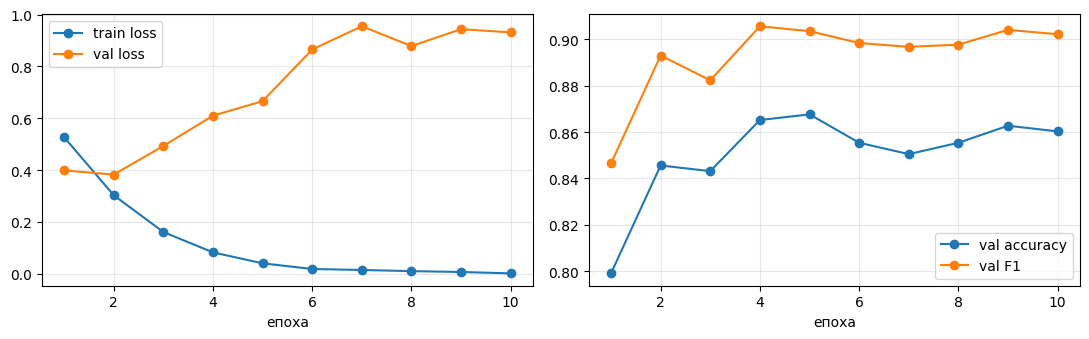

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

hist = pd.DataFrame(trainer_long.state.log_history)
epochs = pd.merge(
    hist.dropna(subset=["loss"])[["epoch", "loss"]],
    hist.dropna(subset=["eval_loss"])[["epoch", "eval_loss", "eval_accuracy", "eval_f1"]],
    on="epoch",
).rename(columns={"loss": "train loss", "eval_loss": "val loss", "eval_accuracy": "val accuracy", "eval_f1": "val F1"})
display(epochs.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(epochs.epoch, epochs["train loss"], "o-", label="train loss")
ax[0].plot(epochs.epoch, epochs["val loss"], "o-", label="val loss")
ax[0].set_xlabel("епоха"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(epochs.epoch, epochs["val accuracy"], "o-", label="val accuracy")
ax[1].plot(epochs.epoch, epochs["val F1"], "o-", label="val F1")
ax[1].set_xlabel("епоха"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

### Тривалість виконання клітинок

In [18]:
import pandas as pd
print(f"Увесь ноутбук: {(time.time() - _t_start) / 60:.1f} хв")
pd.DataFrame(_cell_times, columns=["клітинка (перший рядок коду)", "секунд"]).sort_values("секунд", ascending=False).head(10)

Увесь ноутбук: 5.7 хв


,клітинка (перший рядок коду),секунд
15,set_seed(42),199.0
12,"print(f""Параметрів, що тренуються: {count_para...",80.3
1,import numpy as np,39.9
5,from transformers import pipeline,9.9
8,def tokenize_function(batch):,6.8
3,"raw_datasets = load_dataset(""nyu-mll/glue"", ""m...",6.3
7,"checkpoint = ""bert-base-uncased""",0.7
9,model = AutoModelForSequenceClassification.fro...,0.4
16,import pandas as pd,0.4
11,def compute_metrics(eval_pred):,0.3


---
# Відповіді на питання 0.1 (1-10)

**1. Як довго виконувалися клітинки ноутбуку `01_bert_head`? Чи були проблеми з запуском, які?**

Увесь ноутбук на Colab T4 виконався за **≈ 5,7 хв** (таблиця "Тривалість виконання клітинок" вище):

| що | час |
|---|---|
| тренування на 10 епох (розділ 5, питання 9) | 199 с |
| повне донавчання на 3 епохи + оцінка (розділ 3) | 80 с |
| імпорт бібліотек (`transformers`, `datasets`, `sklearn`) | 40 с |
| завантаження `bert-base-uncased` для `fill-mask` | 10 с |
| токенізація MRPC / завантаження датасету | 7 с / 6 с |
| решта клітинок | < 1 с кожна |

Тобто одна епоха на 3 668 парах триває ≈ 20-25 с: BERT-base маленька (110 млн параметрів), а на T4 ще й працює fp16.

**Проблем із запуском не було**, жодна клітинка не впала. Були лише попередження:
- `You are sending unauthenticated requests to the HF Hub` - без `HF_TOKEN` діють нижчі ліміти на завантаження, для такого обсягу це не заважає;
- `LOAD REPORT` з `UNEXPECTED` / `MISSING` під час завантаження моделі - це очікувано: ваги голів попереднього тренування (`cls.*`) відкидаються, а нова голова `classifier.*` ініціалізується випадково (пояснено в розділі 2 ноутбука).

**2. Як Ви розумієте, що таке токен `[CLS]`? Яким чином він виконує свою функцію?**

`[CLS]` (classification) - спеціальний токен, який токенізатор BERT ставить **першим** у кожну послідовність.
Сам по собі він не означає жодного слова. Його функція - бути "місцем", куди модель збирає зміст усієї послідовності:
- у кожному з 12 шарів self-attention вектор `[CLS]` "дивиться" на всі інші токени обох речень і отримує від них інформацію,
  тож на виході останнього шару його вектор (768 чисел) - це стиснуте представлення всієї пари;
- під час попереднього тренування BERT саме з вектора `[CLS]` розв'язував задачу Next Sentence Prediction ("чи йде речення B після A"),
  тому модель уже навчена складати туди інформацію про зв'язок двох речень;
- у `BertForSequenceClassification` вектор `[CLS]` проходить через pooler (Linear + tanh) і нову голову `classifier`, яка видає 2 логіти.
  Інші токени для класифікації не використовуються - тому під час донавчання модель вчиться "зливати" в `[CLS]` саме те, що потрібно для нашої задачі.

**3. Яке пряме застосування базової моделі `bert-base-uncased`?**

Без донавчання вона вміє лише те, на чому її тренували:
- **Masked Language Modeling** - вгадувати пропущене слово `[MASK]` (pipeline `fill-mask`, як у клітинці вище);
- **Next Sentence Prediction** - визначати, чи є друге речення продовженням першого.

На картці моделі прямо сказано, що вона призначена переважно **для донавчання** під задачі, які використовують усе речення:
класифікація тексту, пар речень (як MRPC), NER, extractive QA. Також її використовують як генератор
ембеддингів (векторів речень/слів) для пошуку чи кластеризації. Для генерації тексту вона не підходить - для цього є моделі на кшталт GPT.

**4. Як Ви вважаєте, чи варто боротися (і якщо так, то яким чином) з проявами сексизму LLM-моделей?**

Так, варто. У прикладі вище модель для "The man worked as a [MASK]" і "The woman worked as a [MASK]" пропонує різні професії
за гендерними стереотипами (про це прямо попереджає розділ *Limitations and bias* картки моделі). Модель не "вважає" так -
вона відтворює статистику текстів, на яких вчилась. Але якщо таку модель поставити, наприклад, у скринінг резюме, стереотип
перетвориться на реальну дискримінацію, і масштабується на тисячі людей. При цьому боротьба не має переходити в цензуру фактів
(наприклад, реальної статистики про професії) - мета в тому, щоб модель не приймала рішення про конкретну людину на основі статі.

Як боротися:
- **дані:** балансувати й фільтрувати корпуси, counterfactual data augmentation (дублювати приклади зі зміненою статтю: he → she);
- **тренування:** донавчання/вирівнювання (SFT, RLHF, DPO) на прикладах без упереджень; методи debiasing ембеддингів;
- **оцінювання:** перевіряти моделі на бенчмарках упереджень (StereoSet, CrowS-Pairs, WinoBias) перед використанням;
- **застосування:** не давати моделі вирішувати чутливі питання (найм, кредити) без людини, прибирати стать і імена з входу, якщо вони не потрібні;
- **прозорість:** документувати упередження в картці моделі, як це зроблено для BERT.

**5. Для чого в секції "Токенізація пари речень" виводяться числа 0 і 1?**

Це `token_type_ids` (segment ids) - номер речення, до якого належить кожен токен: `0` - `[CLS]`, перше речення і перший `[SEP]`,
`1` - друге речення і завершальний `[SEP]`. Обидва речення подаються однією послідовністю, і модель має розрізняти,
де яке. Для цього до ембеддингу кожного токена додається ембеддинг сегмента A або B (разом з ембеддингом позиції).
BERT вчився з ними на задачі NSP, тому для задач з парами речень (як парафрази) вони важливі. У виводі видно, що на
початку йдуть нулі, а останні токени - одиниці.

**6. Що позначають числа 768 і 2, що виводяться після завантаження `AutoModelForSequenceClassification.from_pretrained()`?**

`Linear(in_features=768, out_features=2)` - це нова голова-класифікатор:
- **768** - розмір прихованого стану BERT-base (hidden size): вектор `[CLS]` після pooler має 768 чисел, і саме він подається в голову;
- **2** - кількість виходів = `num_labels=2`: два логіти для класів "не парафраз" (0) і "парафраз" (1). Softmax від них дає ймовірності.

Голова містить 768 × 2 ваг + 2 зсуви = **1 538 параметрів**.

**7. Те що в кістяку (backbone) набагато більше параметрів ніж в голові, це добре чи погано в нашому випадку?**

Добре. Кістяк (≈ 109 млн параметрів) уже **попередньо натренований** на величезному корпусі і "знає" мову: синоніми, граматику,
зв'язки між реченнями. Для MRPC у нас лише ≈ 3,7 тис. тренувальних пар - з нуля на них не натренувати нічого, а от
маленька голова (1,5 тис. параметрів) на такій кількості даних навчається швидко. Тобто вся "важка робота" вже виконана,
і ми лише трохи підлаштовуємо готові знання під задачу (transfer learning).

Мінус - ризик: у повному донавчанні оновлюються всі 109 млн параметрів, і на малому датасеті кістяк легко
перенавчається або "забуває" загальні знання. Тому використовують малий learning rate `2e-5` і лише кілька епох
(це видно з експерименту в питанні 9). Якщо даних зовсім мало, можна заморозити кістяк і тренувати лише голову або використати LoRA.

**8. Що саме вимірюється за допомогою метрик accuracy & F1 в `01_bert_head`?**

Обидві рахуються в `compute_metrics` на **валідаційному наборі MRPC** (408 пар), передбачення - argmax двох логітів:
- **accuracy** - частка пар, для яких модель правильно визначила "парафраз / не парафраз";
- **F1** - для позитивного класу "парафраз" (`f1_score` за замовчуванням рахує для мітки 1): гармонійне середнє
  **precision** (яка частка пар, названих моделлю парафразами, справді є парафразами) і **recall** (яку частку справжніх парафраз модель знайшла).

F1 потрібна, бо класи в MRPC незбалансовані (≈ 68 % пар - парафрази): модель, яка завжди каже "парафраз",
мала б accuracy ≈ 0,68, але F1 одразу показує, що вона нічого не розрізняє. Саме ці дві метрики використовує бенчмарк GLUE для MRPC.

**9. Збільшіть кількість епох тренування в `01_bert_head`, покажіть (скопіювавши результати) що відбувається і чому.**

Експеримент - розділ 5 (10 епох замість 3).

Та сама модель і параметри, але 10 епох замість 3 (розділ 5):

| епоха | train loss | val loss | val accuracy | val F1 |
|---:|---:|---:|---:|---:|
| 1 | 0.5269 | 0.3986 | 0.7990 | 0.8464 |
| 2 | 0.3028 | **0.3823** | 0.8456 | 0.8930 |
| 3 | 0.1610 | 0.4927 | 0.8431 | 0.8824 |
| 4 | 0.0823 | 0.6096 | 0.8652 | **0.9057** |
| 5 | 0.0401 | 0.6658 | **0.8676** | 0.9036 |
| 6 | 0.0183 | 0.8651 | 0.8554 | 0.8985 |
| 7 | 0.0144 | 0.9545 | 0.8505 | 0.8968 |
| 8 | 0.0100 | 0.8783 | 0.8554 | 0.8977 |
| 9 | 0.0066 | 0.9435 | 0.8627 | 0.9041 |
| 10 | 0.0013 | 0.9310 | 0.8603 | 0.9022 |

Для порівняння, 3 епохи в розділі 3: accuracy **0.860**, F1 **0.902**, тобто те саме, що після 10 епох.

**Що відбувається - перенавчання:**
- **train loss падає майже до нуля** (0.53 → 0.0013): модель запам'ятала всі 3 668 тренувальних пар. Для 110 млн параметрів це нескладно;
- **val loss мінімальний на 2-й епосі (0.38), а далі зростає в 2,4 раза** (до 0.93). Модель стає дедалі **впевненішою** у своїх відповідях,
  зокрема й у неправильних. Cross-entropy сильно штрафує впевнені помилки, тому loss росте;
- **accuracy і F1 при цьому стоять на місці** (≈ 0.85-0.87 / 0.89-0.91, коливання в межах 1-2 % - це 4-8 пар із 408).
  Частка правильних відповідей майже не змінюється, змінюється лише впевненість. Тому loss і accuracy "розходяться".

**Чому:** датасет малий, а модель велика. Після 2-4 епох вона вже вивчила все корисне, що можна узагальнити, а далі підганяється під конкретні
тренувальні приклади (шум, випадкові збіги слів). Ці знання на валідацію не переносяться.

**Висновок:** 10 епох тривають у 2,5 раза довше (199 с проти 80 с у розділі 3) і нічого не дають. Оптимально 2-4 епохи. На практиці треба зберігати чекпоінт
з найкращою метрикою на валідації (`load_best_model_at_end=True`) або зупиняти тренування, коли val loss починає рости (`EarlyStoppingCallback`).

**10. Додайте ще 4 перевірки на власних даних в пункті 4 в `01_bert_head`.**

Код - у розділі 4, клітинка `my_pairs`.

| пара | що перевіряю | правильна відповідь | модель | |
|---|---|---|---|---|
| "meeting was postponed because the CEO was ill" / "Since the chief executive was sick, the meeting was moved to a later date" | інші слова, інша будова | парафраз | 97.9 % | ✅ |
| "sold **50** million phones" / "sold **15** million phones" | змінено число | не парафраз | 99.2 % | ❌ |
| "**officer** arrested the **suspect**" / "**suspect** arrested the **officer**" | переставлено, хто що зробив | не парафраз | 99.1 % | ❌ |
| "law **was** approved" / "law was **not** approved" | заперечення | не парафраз | 99.2 % | ❌ |

Плюс три приклади з ноутбука (усі правильні: 86 %, 2.6 %, 99 %).

**Висновок:** перша пара показує, що модель упізнає справжні парафрази навіть без спільних слів (CEO ↔ chief executive, ill ↔ sick, postponed ↔ moved to a later date).
Але на трьох "підступних" парах вона **впевнено помиляється (≈ 99 %)**: якщо майже всі слова в реченнях збігаються, модель вважає їх парафразами
і не помічає, що змінились число, порядок учасників чи з'явилось "not". Тобто вона значною мірою покладається на **перекриття слів**.

Причина в даних. У MRPC пари, які відрізняються одним словом і мають протилежний зміст, майже не трапляються. Невідповідні пари там зазвичай
відрізняються багатьма словами, тож модель вивчила просте правило "багато спільних слів → парафраз". Щоб це виправити, додають такі приклади
в тренування (наприклад, датасет PAWS, зібраний саме з перестановок слів), або перевіряють числа й заперечення окремими правилами.